# 02 · Crop Recommendation Models: Baselines vs Stacked Ensemble

All logic lives in `ml-service/training/crop_training.py` (shared with `python -m training.train_crop`), so the notebook and the production artifacts can never drift apart.

**Protocol:** label encoding → stratified 80/20 split (`random_state=42`) → StandardScaler fitted on the training set only → stratified 5-fold CV on the training set (scaler inside a Pipeline, so no leakage) → final scores on the untouched 20% test set.

In [1]:
# Locate the project root (works when launched from notebooks/ or the repo root)
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml-service").is_dir())
ML = ROOT / "ml-service"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
sys.path.insert(0, str(ML))  # lets us import the shared training/ package
print("Project root:", ROOT)

Project root: D:\AI powered\agri-dss


In [2]:
import json
import pandas as pd
from IPython.display import Image, display
from training import crop_training as ct, charts

df_raw = ct.load_dataset()
ct.data_quality_report(df_raw)

{'rows': 2200,
 'classes': 22,
 'missing_values': {'N': 0,
  'P': 0,
  'K': 0,
  'temperature': 0,
  'humidity': 0,
  'ph': 0,
  'rainfall': 0,
  'label': 0},
 'duplicate_rows': 0,
 'rows_per_class': {'min': 100, 'max': 100}}

## 1. Preprocessing

In [3]:
df = ct.clean(df_raw)
d = ct.prepare(df)
print("train:", d["X_train"].shape, "| test:", d["X_test"].shape, "| classes:", len(d["encoder"].classes_))
pd.DataFrame(d["X_train_s"], columns=ct.FEATURES).describe().loc[["mean", "std"]].round(3)

train: (1760, 7) | test: (440, 7) | classes: 22


,N,P,K,temperature,humidity,ph,rainfall
mean,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 2. Models
| Role | Model |
|---|---|
| Baseline | Decision Tree, Random Forest, Logistic Regression, SVM (RBF) |
| **Stacked ensemble** | Base: Random Forest + Extra Trees + Gradient Boosting → Meta: Logistic Regression on out-of-fold class probabilities (5-fold `StackingClassifier`) |

In [4]:
ct.build_stack()

,estimators,"[('rf', ...), ('et', ...), ...]"
,final_estimator,LogisticRegre...ndom_state=42)
,cv,StratifiedKFo... shuffle=True)
,stack_method,'predict_proba'
,n_jobs,1
,passthrough,False
,verbose,0
,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2


## 3. Training and evaluation
This takes a few minutes, mostly gradient boosting inside the stacked model's cross-validation.

In [5]:
results, fitted = ct.evaluate_all(d)
results[["cv_accuracy_mean", "cv_accuracy_std", "cv_f1_macro_mean", "test_accuracy",
         "test_precision_macro", "test_recall_macro", "test_f1_macro", "fit_seconds"]].round(4)

Decision Tree        cv_acc=0.9852±0.0068 test_acc=0.9795 f1=0.9794 (0.19s)


Random Forest        cv_acc=0.9932±0.0053 test_acc=0.9955 f1=0.9955 (6.56s)


Logistic Regression  cv_acc=0.9682±0.0066 test_acc=0.9727 f1=0.9725 (0.42s)


SVM (RBF)            cv_acc=0.9824±0.0049 test_acc=0.9886 f1=0.9887 (0.57s)


Stacked Ensemble     cv_acc=0.9943±0.0048 test_acc=0.9955 f1=0.9955 (707.49s)


,cv_accuracy_mean,cv_accuracy_std,cv_f1_macro_mean,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,fit_seconds
model,,,,,,,,
Decision Tree,0.9852,0.0068,0.9852,0.9795,0.9806,0.9795,0.9794,0.03
Random Forest,0.9932,0.0053,0.9931,0.9955,0.9957,0.9955,0.9955,1.23
Logistic Regression,0.9682,0.0066,0.9678,0.9727,0.9740,0.9727,0.9725,0.10
SVM (RBF),0.9824,0.0049,0.9822,0.9886,0.9896,0.9886,0.9887,0.07
Stacked Ensemble,0.9943,0.0048,0.9943,0.9955,0.9957,0.9955,0.9955,231.99


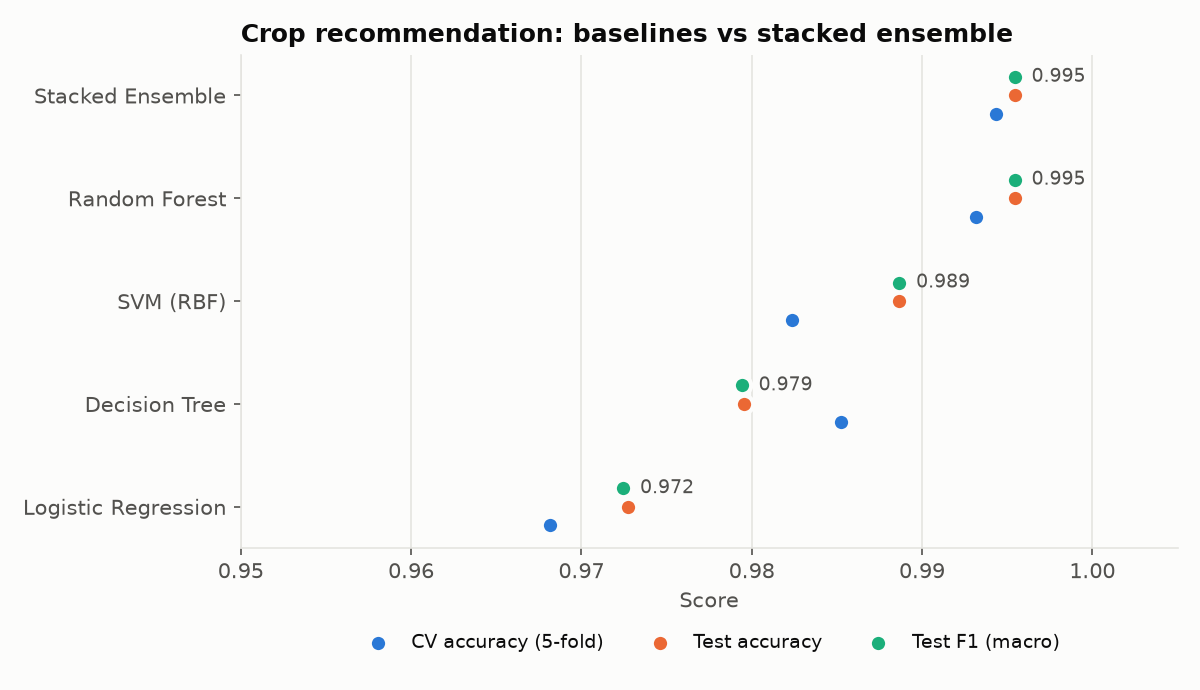

In [6]:
charts.model_comparison(results, REPORTS / "model_comparison.png")
display(Image(REPORTS / "model_comparison.png"))

## 4. Stacked ensemble: confusion matrix and per-class report

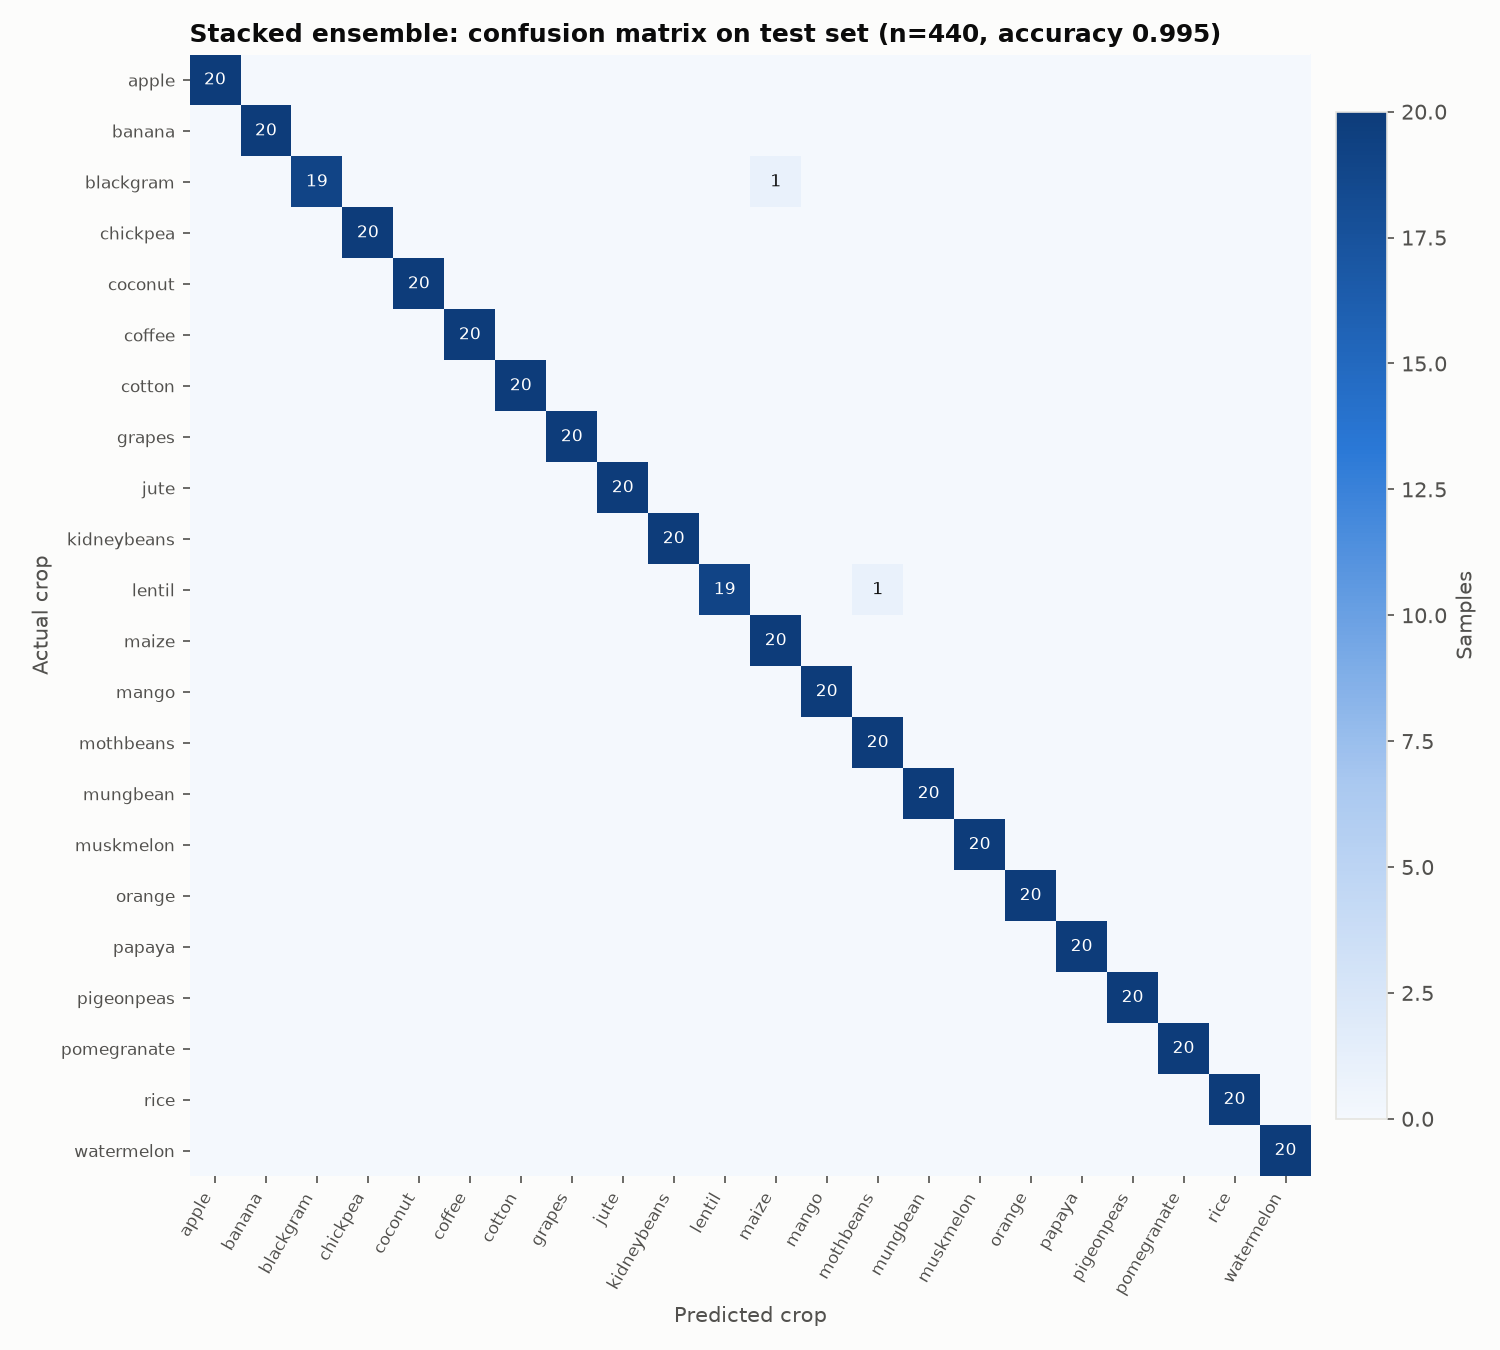

In [7]:
stack = fitted[ct.STACK_NAME]
diag = ct.stack_diagnostics(stack, d)
charts.confusion_matrix_plot(diag["confusion_matrix"], diag["labels"], REPORTS / "confusion_matrix_stack.png")
display(Image(REPORTS / "confusion_matrix_stack.png"))

In [8]:
report = pd.DataFrame(diag["classification_report"]).T
weak = report.iloc[:-3].sort_values("f1-score").head(5)
print("Lowest-F1 crops:")
weak.round(3)

Lowest-F1 crops:


,precision,recall,f1-score,support
blackgram,1.000,0.95,0.974,20.0
lentil,1.000,0.95,0.974,20.0
maize,0.952,1.00,0.976,20.0
mothbeans,0.952,1.00,0.976,20.0
coconut,1.000,1.00,1.000,20.0


## 5. Feature importance
Permutation importance is model-agnostic: it shuffles one feature at a time on the test set and measures the drop in accuracy of the **whole stack**. The Random Forest base model's impurity importance is shown alongside for comparison.

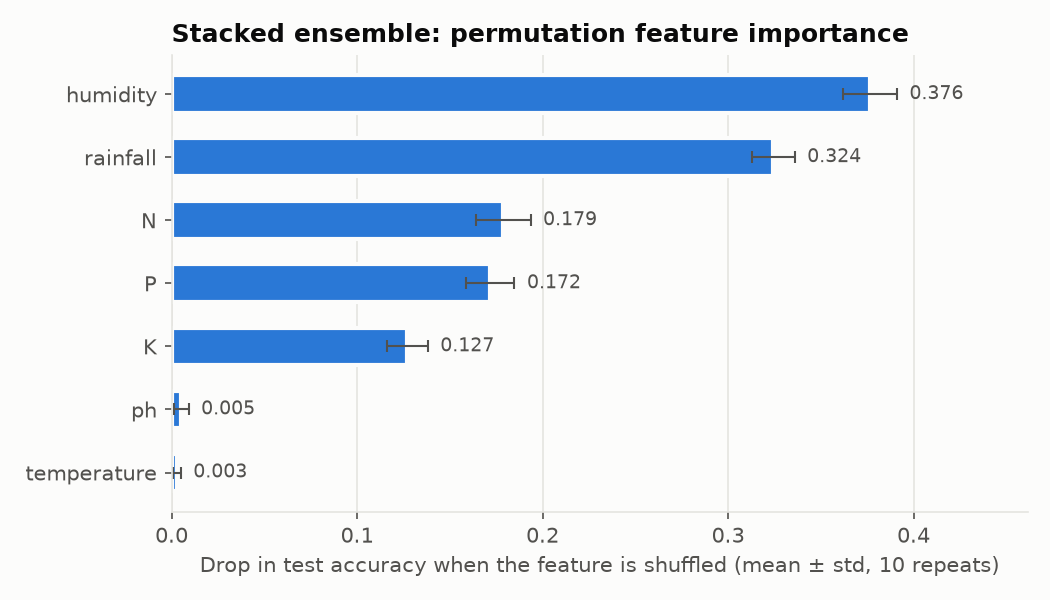

,permutation_mean,rf_impurity
humidity,0.3764,0.2119
rainfall,0.3243,0.2215
N,0.1789,0.1039
P,0.1718,0.1537
K,0.1270,0.1792
ph,0.0052,0.0539
temperature,0.0027,0.0758


In [9]:
charts.feature_importance_plot(diag["permutation_importance"], REPORTS / "feature_importance.png")
display(Image(REPORTS / "feature_importance.png"))
pd.DataFrame({
    "permutation_mean": {k: v["mean"] for k, v in diag["permutation_importance"].items()},
    "rf_impurity": diag["rf_impurity_importance"],
}).sort_values("permutation_mean", ascending=False).round(4)

## 6. Save artifacts
- `ml-service/models/crop_stack.joblib`, `scaler.joblib`, `label_encoder.joblib`, `crop_model_meta.json`
- `ml-service/knowledge/crop_profiles.json` (per-crop mean/std/min/max)
- `reports/metrics.json` (full comparison + diagnostics)

In [10]:
meta = ct.save_artifacts(stack, d, df, results, diag, ct.data_quality_report(df_raw))
meta

{'model_version': 'crop-stack-v1-20261112',
 'trained_at': '2026-11-12T04:57:45+00:00',
 'sklearn_version': '1.7.2',
 'features': ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'],
 'classes': ['apple',
  'banana',
  'blackgram',
  'chickpea',
  'coconut',
  'coffee',
  'cotton',
  'grapes',
  'jute',
  'kidneybeans',
  'lentil',
  'maize',
  'mango',
  'mothbeans',
  'mungbean',
  'muskmelon',
  'orange',
  'papaya',
  'pigeonpeas',
  'pomegranate',
  'rice',
  'watermelon'],
 'test_accuracy': 0.9955,
 'test_f1_macro': 0.9955}

## 7. Composite score demo
The API ranks crops by `final = 0.6 × probability + 0.2 × season_score + 0.2 × weather_score`. Below we score one rice-like sample in July (Kharif).

In [11]:
from types import SimpleNamespace
from app.schemas import CropRequest
from app.services.crop import recommend

kb = {n: json.loads((ML / "knowledge" / f"{n}.json").read_text()) for n in ("crop_profiles", "crop_seasons")}
registry = SimpleNamespace(crop_model=stack, crop_scaler=d["scaler"], crop_encoder=d["encoder"], knowledge=kb,
                           status={"crop": SimpleNamespace(version=meta["model_version"])})
req = CropRequest(N=90, P=42, K=43, temperature=21, humidity=82, ph=6.5, rainfall=203, month=7)
pd.DataFrame(recommend(req, registry)["top"]).drop(columns=["weather_detail"])

,crop,probability,season_score,weather_score,final_score,seasons
0,rice,0.9804,1.0,0.9457,0.9774,[Kharif]
1,pigeonpeas,0.0009,1.0,0.5333,0.3072,[Kharif]
2,jute,0.0028,1.0,0.5217,0.3060,"[Kharif, Zaid]"
3,papaya,0.0009,1.0,0.4947,0.2995,"[Kharif, Rabi, Zaid]"
4,cotton,0.0008,1.0,0.3963,0.2797,[Kharif]
